# Olist Brazilian E-commerce Marketplace: Data Mining and Predictive Analytics

**Exam focus:** marketplace exploration, product combinations, seller segmentation, unusual-order detection and delivery prediction.

## Business context
Olist wants to understand purchasing patterns, improve seller performance and retention, identify orders that may need operational review, and improve delivery reliability. This notebook analyses the supplied Olist marketplace data and translates the results into practical recommendations.

## Questions to be answered
1. What does the data reveal about the marketplace, and what preparation is required?
2. Which product categories are frequently purchased together, and how can Olist use these relationships to increase sales?
3. What seller segments can be identified from sales and service characteristics, and how should Olist serve and retain them?
4. Which orders appear unusual and deserve operational review?
5. Can Olist predict late delivery and the number of days between purchase and delivery?

## 0. Imports and configuration

In [119]:
import os
import warnings
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.inspection import permutation_importance
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_DIR = "."

def f(filename):
    return os.path.join(DATA_DIR, filename)

RANDOM_STATE = 42

## 1. Loading the data

In [120]:
required_files = [
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_products_dataset.csv",
    "product_category_name_translation.csv",
    "olist_customers_dataset.csv",
    "olist_sellers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    
]
missing_files = [name for name in required_files if not os.path.exists(f(name))]
if missing_files:
    raise FileNotFoundError(
        "These required files were not found in DATA_DIR:\n"
        + "\n".join(missing_files)
        + "\nCheck DATA_DIR and the CSV filenames."
    )

date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
orders = pd.read_csv(f("olist_orders_dataset.csv"), parse_dates=date_cols)
items = pd.read_csv(f("olist_order_items_dataset.csv"))
products = pd.read_csv(f("olist_products_dataset.csv"))
translations = pd.read_csv(f("product_category_name_translation.csv"))
customers = pd.read_csv(f("olist_customers_dataset.csv"))
sellers = pd.read_csv(f("olist_sellers_dataset.csv"))
geolocation = pd.read_csv(f("olist_geolocation_dataset.csv"))
payments = pd.read_csv(f("olist_order_payments_dataset.csv"))

reviews_path = f("olist_order_reviews_dataset.csv")
reviews = pd.read_csv(reviews_path) if os.path.exists(reviews_path) else None

datasets = {
    "orders": orders, "items": items, "products": products,
    "category translations": translations, "customers": customers,
    "sellers": sellers, "geolocation": geolocation, "payments": payments
}
if reviews is not None:
    datasets["reviews"] = reviews

overview = pd.DataFrame({
    "dataset": list(datasets.keys()),
    "rows": [len(x) for x in datasets.values()],
    "columns": [x.shape[1] for x in datasets.values()],
    "duplicate_rows": [x.duplicated().sum() for x in datasets.values()]
})
display(overview)

,dataset,rows,columns,duplicate_rows
0,orders,99441,8,0
1,items,112650,7,0
2,products,32951,9,0
3,category translations,71,2,0
4,customers,99441,5,0
5,sellers,3095,4,0
6,geolocation,1000163,5,261831
7,payments,103886,5,0
8,reviews,99224,7,0


## 2. Task 1 - Exploring the data and preparing it

I will first look at the size, structure and missing values of every table. Then I will check order status, order dates, prices and freight. Then I will test the data for errors and prepare it for the later tasks.

The tables connect through ID columns. The order-items table is the main source, because one order can contain many items and can involve more than one seller.

### 2.1 Structure and missing values

I will print the first rows of each table and the share of missing values in each column.

In [121]:
for name, frame in datasets.items():
    print(f"\n{name.upper()} - {frame.shape[0]:,} rows x {frame.shape[1]} columns")
    display(frame.head(5))
    missing = (frame.isna().mean() * 100).sort_values(ascending=False)
    display(missing[missing > 0].head(12).rename("missing_percent").to_frame())


ORDERS - 99,441 rows x 8 columns


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


,missing_percent
order_delivered_customer_date,2.981668
order_delivered_carrier_date,1.793023
order_approved_at,0.160899



ITEMS - 112,650 rows x 7 columns


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,missing_percent


... (17 outputs left out)

,missing_percent



REVIEWS - 99,224 rows x 7 columns


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


,missing_percent
review_comment_title,88.341530
review_comment_message,58.702532


**observation**
- 2.98% of orders have no customer delivery date, 1.79% have no carrier date and 0.16% have no approval date. I think this is because those orders were not finished (shipped, cancelled and so on). I will check this in the lower cells later.
- 1.85% of products have no category, name length, description length or photo count. Only 0.006% (2 products) have no weight or size.
- 88% reviews have no title and 59% have no comment. I will not use the review text, so this is not a problem.
- 261,831 rows in gelocation are exact duplicates. This is why I will use one median point per postal code later.
- Customers, sellers, items and payments have no missing values.

### 2.2 Order status, time trend, price and freight

I will count the orders by status, plot orders per month, and describe the price and freight values. I will also print simple findings from the numbers.

,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


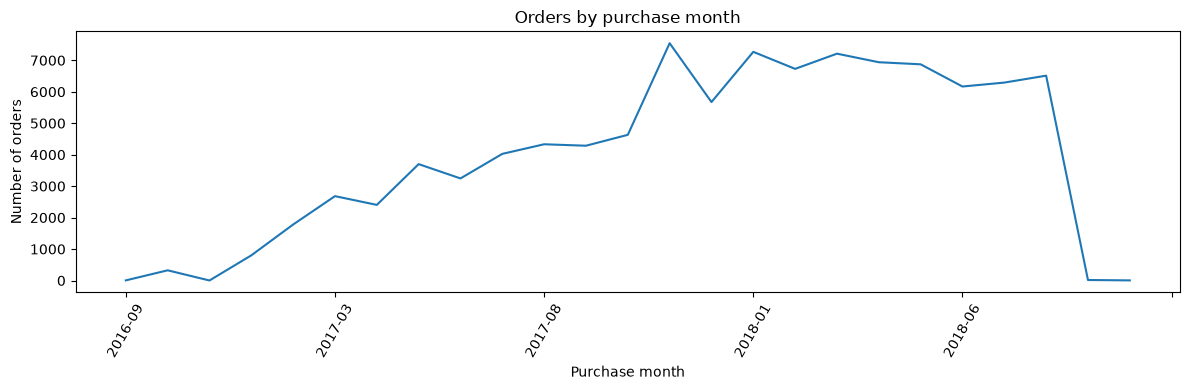

,count,mean,std,min,25%,50%,75%,max
price,112650.0,120.653739,183.633928,0.85,39.9,74.99,134.9,6735.0


,count,mean,std,min,25%,50%,75%,max
freight_value,112650.0,19.99032,15.806405,0.0,13.08,16.26,21.15,409.68


I found that 97.0% of orders were delivered.
I found orders from 2016-09 to 2018-10.
I found that the busiest month was 2017-11 with 7,544 orders.
I found very low order counts in these months (the data may be incomplete): ['2016-09', '2016-10', '2016-12', '2018-09', '2018-10']


In [122]:
display(orders["order_status"].value_counts(dropna=False).rename("orders").to_frame())

purchase_month = (
    orders.dropna(subset=["order_purchase_timestamp"])
    .assign(month=lambda x: x["order_purchase_timestamp"].dt.to_period("M").astype(str))
    .groupby("month").size()
)
plt.figure(figsize=(12, 4))
purchase_month.plot()
plt.title("Orders by purchase month")
plt.xlabel("Purchase month")
plt.ylabel("Number of orders")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

for col in ["price", "freight_value"]:
    display(items[col].describe().to_frame().T)

# Findings printed from the data
status_share = orders["order_status"].value_counts(normalize=True)
print(f"I found that {status_share['delivered']:.1%} of orders were delivered.")
print(f"I found orders from {purchase_month.index[0]} to {purchase_month.index[-1]}.")
print(f"I found that the busiest month was {purchase_month.idxmax()} with {purchase_month.max():,} orders.")
weak_months = purchase_month[purchase_month < 0.1 * purchase_month.max()]
print("I found very low order counts in these months (the data may be incomplete):", list(weak_months.index))

**What I have seen**
- Most orders (96,478, about 97%) were delivered. Only a few were shipped (1,107), cancelled (625) or unavailable (609).
- Prices are very skewed. The mean price is 120.65 but the median is only 74.99, and the highest price is 6,735.
- Freight is also skewed. The mean is 19.99, the median is 16.26 and the highest is 409.68.
- The printed list above shows any months with very few orders. These are at the start and end of the data, so they most likely reflect incomplete data, not a real fall in sales.

**Why it matters:** the skew means averages can mislead, so I will use medians and log values in later tasks.

### 2.3 Data quality checks

I will check for duplicate IDs, and for dates that do not make sense (for example, delivery before purchase). I will also check how many orders have no items.

In [123]:
checks = {
    "duplicate order IDs in orders": orders["order_id"].duplicated().sum(),
    "duplicate product IDs in products": products["product_id"].duplicated().sum(),
    "duplicate seller IDs in sellers": sellers["seller_id"].duplicated().sum(),
    "duplicate customer IDs in customers": customers["customer_id"].duplicated().sum(),
    "duplicate order-item keys": items.duplicated(["order_id", "order_item_id"]).sum()
}
display(pd.Series(checks, name="count").to_frame())

delivered_only = orders[orders["order_status"] == "delivered"]
quality = {
    "Delivered orders with no delivery date": delivered_only["order_delivered_customer_date"].isna().sum(),
    "Delivery date before purchase date": (orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"]).sum(),
    "Carrier date before purchase date": (orders["order_delivered_carrier_date"] < orders["order_purchase_timestamp"]).sum(),
    "Delivery date before carrier date": (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]).sum(),
    "Orders with no items": (~orders["order_id"].isin(items["order_id"])).sum(),
    "Items with zero freight": (items["freight_value"] == 0).sum(),
}
if reviews is not None:
    quality["Orders with more than one review"] = reviews["order_id"].duplicated().sum()
quality = pd.Series(quality, name="count")
display(quality.to_frame())

for name, value in quality.items():
    print(f"I found {value:,} cases of: {name.lower()}.")

no_item_status = orders.loc[~orders["order_id"].isin(items["order_id"]), "order_status"].value_counts()
print("\nI found that orders with no items have these statuses:")
display(no_item_status.to_frame("orders"))

,count
duplicate order IDs in orders,0
duplicate product IDs in products,0
duplicate seller IDs in sellers,0
duplicate customer IDs in customers,0
duplicate order-item keys,0


,count
Delivered orders with no delivery date,8
Delivery date before purchase date,0
Carrier date before purchase date,166
Delivery date before carrier date,23
Orders with no items,775
Items with zero freight,383
Orders with more than one review,551


I found 8 cases of: delivered orders with no delivery date.
I found 0 cases of: delivery date before purchase date.
I found 166 cases of: carrier date before purchase date.
I found 23 cases of: delivery date before carrier date.
I found 775 cases of: orders with no items.
I found 383 cases of: items with zero freight.
I found 551 cases of: orders with more than one review.

I found that orders with no items have these statuses:


,orders
order_status,
unavailable,603
canceled,164
created,5
invoiced,2
shipped,1


**What I found**
- There were **no duplicate IDs** in the five tables that have a unique key. The other tables (geolocation, payments, reviews) can legally repeat an ID, so I did not use the same test on them.
- The printed counts above show the date errors (if any) and the orders with no items. I will handle them in the preparation step, date errors are left out of the delivery model, and orders with no items are kept out of the item-based tasks.
- Orders with no items are mostly unavailable or cancelled. I will use this again in Task 4.

### 2.4 Data preparation


| Step | Reason |
|---|---|
| Read dates as dates | So I can work out waiting times and monthly trends. |
| Translate category names to English | Easier to read. I will add the 2 missing translations. Products with no category become "unknown". |
| Use the median latitude and longitude for each postal code | The geolocation table has many points per code. One point per code is enough to estimate distance. |
| Treat zero weight or size as missing | A real product cannot weigh 0 g. |
| Work out the straight-line seller-to-customer distance | Distance is a likely driver of freight and delivery time. |
| Combine item rows into one row per order | An order with many items must count as one delivery. |
| Add the average review score per order | I will use it to check results in Tasks 1 and 4. |
| Add the unique customer ID | `customer_id` changes for every order. `customer_unique_id` finds repeat customers. |

In [124]:
geo = (
    geolocation.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
    .median()
)

extra_translations = pd.DataFrame({
    "product_category_name": [
        "pc_gamer",
        "portateis_cozinha_e_preparadores_de_alimentos"
    ],
    "product_category_name_english": [
        "pc_gamer",
        "portable_kitchen_food_preparers"
    ]
})
translations = pd.concat([translations, extra_translations], ignore_index=True)
translations = translations.drop_duplicates("product_category_name", keep="last")

products = products.merge(translations, how="left", on="product_category_name")
products["category"] = products["product_category_name_english"].fillna("unknown")
products["volume_cm3"] = (
    products["product_length_cm"] *
    products["product_height_cm"] *
    products["product_width_cm"]
)

for col in ["product_weight_g", "volume_cm3"]:
    products.loc[products[col] <= 0, col] = np.nan

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (
        np.sin((lat2-lat1)/2)**2
        + np.cos(lat1) * np.cos(lat2) * np.sin((lon2-lon1)/2)**2
    )
    return 6371 * 2 * np.arcsin(np.sqrt(a))

item_data = (
    items.merge(
        products[["product_id", "category", "product_weight_g", "volume_cm3"]],
        on="product_id", how="left"
    )
    .merge(sellers, on="seller_id", how="left")
    .merge(orders, on="order_id", how="left")
    .merge(customers, on="customer_id", how="left")
)

item_data = item_data.join(
    geo.rename(columns={"geolocation_lat": "seller_lat", "geolocation_lng": "seller_lng"}),
    on="seller_zip_code_prefix"
)
item_data = item_data.join(
    geo.rename(columns={"geolocation_lat": "customer_lat", "geolocation_lng": "customer_lng"}),
    on="customer_zip_code_prefix"
)
item_data["distance_km"] = haversine(
    item_data["seller_lat"], item_data["seller_lng"],
    item_data["customer_lat"], item_data["customer_lng"]
)

payment_summary = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    installments=("payment_installments", "max"),
    payment_type=("payment_type", lambda x: x.mode().iloc[0] if not x.mode().empty else "unknown")
).reset_index()

order_items = item_data.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_sellers=("seller_id", "nunique"),
    sales_value=("price", "sum"),
    freight_value=("freight_value", "sum"),
    total_weight_g=("product_weight_g", "sum"),
    total_volume_cm3=("volume_cm3", "sum"),
    distance_km=("distance_km", "mean"),
    seller_state=("seller_state", "first"),
    first_category=("category", "first")
).reset_index()

order_data = (
    orders.merge(order_items, on="order_id", how="left")
    .merge(customers[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
    .merge(payment_summary, on="order_id", how="left")
)

if reviews is not None:
    review_order = reviews.groupby("order_id")["review_score"].mean().rename("review_score").reset_index()
    order_data = order_data.merge(review_order, on="order_id", how="left")
else:
    order_data["review_score"] = np.nan

order_data["delivery_days"] = (
    order_data["order_delivered_customer_date"] -
    order_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_data["estimated_days"] = (
    order_data["order_estimated_delivery_date"] -
    order_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_data["late"] = np.where(
    order_data["order_delivered_customer_date"].notna(),
    (
        order_data["order_delivered_customer_date"] >
        order_data["order_estimated_delivery_date"]
    ).astype(float),
    np.nan
)

print("Joined item-level rows:", f"{len(item_data):,}")
print("Order-level rows:", f"{len(order_data):,}")
display(order_data.head())

Joined item-level rows: 112,650
Order-level rows: 99,441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,n_items,n_sellers,sales_value,freight_value,total_weight_g,total_volume_cm3,distance_km,seller_state,first_category,customer_unique_id,customer_state,payment_value,installments,payment_type,review_score,delivery_days,estimated_days,late
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1.0,1.0,29.99,8.72,500.0,1976.0,18.681711,SP,housewares,7c396fd4830fd04220f754e42b4e5bff,SP,38.71,1.0,voucher,4.0,8.436574,15.544063,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1.0,1.0,118.70,22.76,400.0,4693.0,861.035367,SP,perfumery,af07308b275d755c9edb36a90c618231,BA,141.46,1.0,boleto,4.0,13.782037,19.137766,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1.0,1.0,159.90,19.22,420.0,9576.0,514.547140,SP,auto,3a653a41f6f9fc3d2a113cf8398680e8,GO,179.12,3.0,credit_card,5.0,9.394213,26.639711,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1.0,1.0,45.00,27.20,450.0,6000.0,1821.802656,MG,pet_shop,7c142cf63193a1473d2e66489a9ae977,RN,72.20,1.0,credit_card,5.0,13.208750,26.188819,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1.0,1.0,19.90,8.72,250.0,11475.0,29.593095,SP,stationery,72632f0f9dd73dfee390c9b22eb56dd6,SP,28.62,1.0,credit_card,5.0,2.873877,12.112049,0.0


I have seen that the item-level table has 112,650 rows and the order-level table has 99,441 rows (one per order). The row counts match the raw tables, so the joins did not create duplicate rows.

### 2.5 Marketplace patterns

I will look at which categories sell the most, where customers and sellers are, how reviews relate to late delivery, and what is linked to freight cost. I will not claim that any link proves cause and effect.

,items_sold,orders,sellers,sales_value,average_item_price
category,,,,,
bed_bath_table,11115,9417,196,1036988.68,93.296327
health_beauty,9670,8836,492,1258681.34,130.163531
sports_leisure,8641,7720,481,988048.97,114.344285
computers_accessories,7827,6689,287,911954.32,116.513903
furniture_decor,8334,6449,370,729762.49,87.564494
housewares,6964,5884,468,632248.66,90.788148
watches_gifts,5991,5624,101,1205005.68,201.135984
telephony,4545,4199,149,323667.53,71.213978
auto,4235,3897,383,592720.11,139.957523


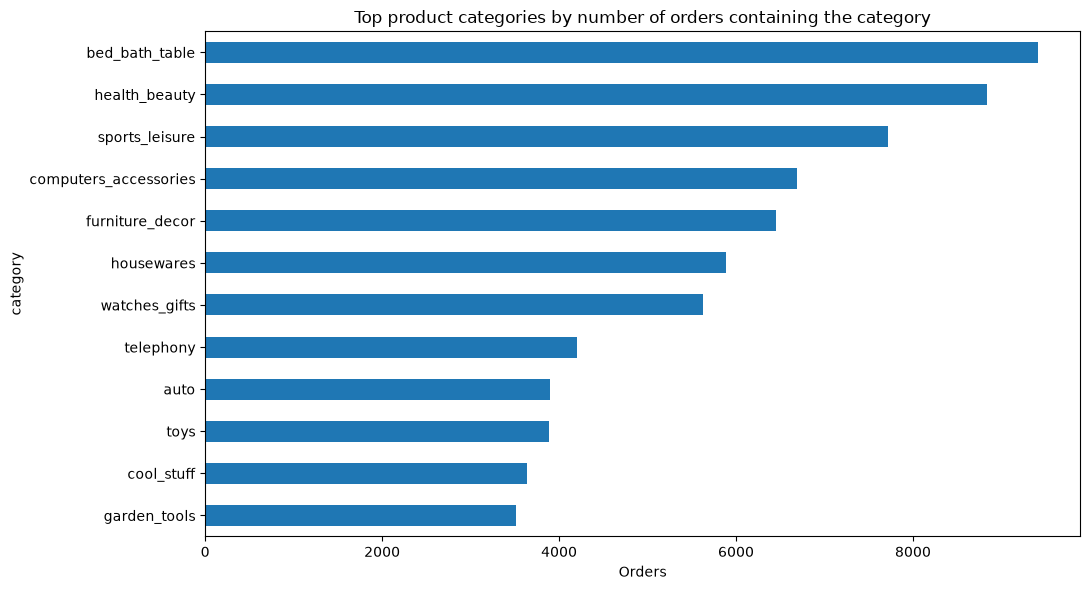

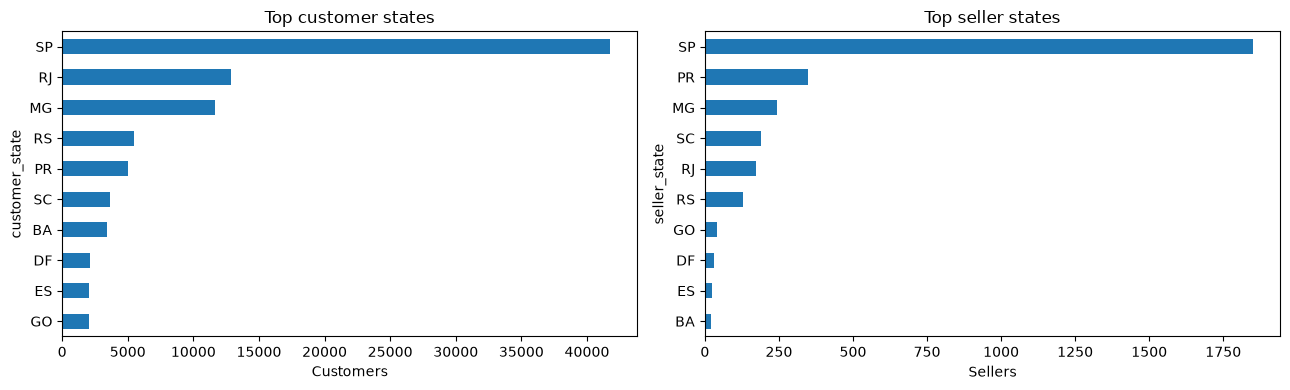

,share
payment_type,
credit_card,0.739
boleto,0.190
voucher,0.056
debit_card,0.015
not_defined,0.000


,share
review_score,
1,0.115
2,0.032
3,0.082
4,0.193
5,0.578


,spearman_correlation_with_freight
distance_km,0.59
total_weight_g,0.49
total_volume_cm3,0.43
sales_value,0.47


I found that SP has 42.0% of customers.
I found that SP has 59.7% of sellers.
I found that credit_card is the most used payment type.
I found that freight is most strongly linked to distance_km (correlation 0.59).
I found that on-time orders have an average review score of 4.29, but late orders have 2.57.


In [125]:
category_summary = (
    item_data.groupby("category")
    .agg(
        items_sold=("order_id", "size"),
        orders=("order_id", "nunique"),
        sellers=("seller_id", "nunique"),
        sales_value=("price", "sum"),
        average_item_price=("price", "mean")
    )
    .sort_values("orders", ascending=False)
)
display(category_summary.head(15))

plt.figure(figsize=(11, 6))
category_summary.head(12)["orders"].sort_values().plot(kind="barh")
plt.title("Top product categories by number of orders containing the category")
plt.xlabel("Orders")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
customers["customer_state"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top customer states")
axes[0].set_xlabel("Customers")
sellers["seller_state"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Top seller states")
axes[1].set_xlabel("Sellers")
plt.tight_layout()
plt.show()

display(payments["payment_type"].value_counts(normalize=True).round(3).rename("share").to_frame())
if reviews is not None:
    display(reviews["review_score"].value_counts(normalize=True).sort_index().round(3).rename("share").to_frame())

freight_corr = (
    order_data[["freight_value", "distance_km", "total_weight_g", "total_volume_cm3", "sales_value"]]
    .corr(method="spearman")["freight_value"].drop("freight_value")
)
display(freight_corr.round(2).rename("spearman_correlation_with_freight").to_frame())

top_cust = customers["customer_state"].value_counts(normalize=True)
top_sell = sellers["seller_state"].value_counts(normalize=True)
print(f"I found that {top_cust.index[0]} has {top_cust.iloc[0]:.1%} of customers.")
print(f"I found that {top_sell.index[0]} has {top_sell.iloc[0]:.1%} of sellers.")
print(f"I found that {payments['payment_type'].value_counts(normalize=True).index[0]} is the most used payment type.")
print(f"I found that freight is most strongly linked to {freight_corr.abs().idxmax()} (correlation {freight_corr[freight_corr.abs().idxmax()]:.2f}).")

rv = order_data.dropna(subset=["review_score", "late"])
if len(rv) > 0 and rv["late"].nunique() == 2:
    rv_mean = rv.groupby("late")["review_score"].mean()
    print(f"I found that on-time orders have an average review score of {rv_mean.loc[0.0]:.2f}, but late orders have {rv_mean.loc[1.0]:.2f}.")

**Observed**
- bed_bath_table (9,417), health_beauty (8,836), sports_leisure (7,720), computers_accessories (6,689), furniture_decor (6,449) and housewares (5,884), are top categories by orders.
- health_beauty earns the most (about 1.26 million). watches_gifts earns about 1.2 million from only 5,624 orders and only 101 sellers, so each sale is worth more and the category depends on few sellers meaning most orders is not the same as most money
- The printed lines above show where customers and sellers are, the main payment type, what freight is linked to, and how late delivery relates to review scores.

**Why it matters:** customers are concentrated in a few states, and late delivery is linked to worse reviews. This is why delivery reliability is a business priority.

## 3. Task 2 - Product categories frequently purchased together

I will use market basket analysis where each order is one basket, and I count each category once per order. For every pair of categories I will calculate:

- **Support:** the share of baskets that contain both categories.
- **Confidence (A to B):** of the baskets with A, the share that also have B.
- **Lift:** how much more often A and B appear together than by chance. Above 1 means they go together more than expected.

I will do this at two levels:
1. **Order level:** categories in the same order.
2. **Customer level:** all categories one customer ever bought (using `customer_unique_id`). This can find links between orders placed on different days.

I will also check how many baskets have more than one category, because pairs can only come from those.

In [126]:
basket_rows = item_data.dropna(subset=["order_id", "category"]).copy()
basket_rows["category"] = basket_rows["category"].astype(str).str.strip()
basket_rows = basket_rows[
    (basket_rows["category"] != "") &
    (basket_rows["category"].str.lower() != "unknown")
]

def make_pair_table(basket, min_support=0.0001):
    """Support, confidence and lift for every pair of categories in the baskets."""
    n_baskets = len(basket)
    category_counts, pair_counts = {}, {}
    for categories in basket:
        for cat in categories:
            category_counts[cat] = category_counts.get(cat, 0) + 1
        for a, b in combinations(categories, 2):
            pair_counts[(a, b)] = pair_counts.get((a, b), 0) + 1

    rows = []
    for (a, b), count_ab in pair_counts.items():
        support = count_ab / n_baskets
        if support < min_support:
            continue
        support_a = category_counts[a] / n_baskets
        support_b = category_counts[b] / n_baskets
        rows.append({
            "category_A": a, "category_B": b,
            "orders_together": count_ab,
            "support": support,
            "confidence_A_to_B": count_ab / category_counts[a],
            "confidence_B_to_A": count_ab / category_counts[b],
            "lift": support / (support_a * support_b)
        })
    columns = ["category_A", "category_B", "orders_together", "support",
               "confidence_A_to_B", "confidence_B_to_A", "lift"]
    return pd.DataFrame(rows, columns=columns), n_baskets

basket_order = basket_rows.groupby("order_id")["category"].apply(lambda x: sorted(set(x)))
basket_customer = basket_rows.groupby("customer_unique_id")["category"].apply(lambda x: sorted(set(x)))

pairs_order, n_order = make_pair_table(basket_order)
pairs_customer, n_customer = make_pair_table(basket_customer)

for label, basket, pairs in [("order", basket_order, pairs_order), ("customer", basket_customer, pairs_customer)]:
    multi_share = (basket.apply(len) > 1).mean()
    print(f"I found {len(basket):,} baskets at {label} level, and only {multi_share:.1%} of them have more than one category.")

MIN_TOGETHER = 20   # I ignore pairs seen fewer than 20 times because their lift is unstable.

def show_pairs(pairs, label):
    print(f"\n=== {label}: most frequent pairs ===")
    display(pairs.sort_values("orders_together", ascending=False).head(10).round(4))
    strong = pairs[(pairs["orders_together"] >= MIN_TOGETHER) & (pairs["lift"] > 1)]
    strong = strong.sort_values("lift", ascending=False)
    print(f"=== {label}: pairs with at least {MIN_TOGETHER} baskets and lift above 1 ===")
    if strong.empty:
        print("None.")
    else:
        display(strong.head(10).round(4))
    return strong

strong_order = show_pairs(pairs_order, "Order level")
strong_customer = show_pairs(pairs_customer, "Customer level")

if not strong_order.empty:
    top = strong_order.iloc[0]
    print(f"\nI found that at order level the strongest pair is {top['category_A']} + {top['category_B']} "
          f"({int(top['orders_together'])} orders, lift {top['lift']:.2f}).")
if not strong_customer.empty:
    top = strong_customer.iloc[0]
    print(f"I found that at customer level the strongest pair is {top['category_A']} + {top['category_B']} "
          f"({int(top['orders_together'])} customers, lift {top['lift']:.2f}).")

I found 97,277 baskets at order level, and only 0.7% of them have more than one category.
I found 94,108 baskets at customer level, and only 2.4% of them have more than one category.

=== Order level: most frequent pairs ===


,category_A,category_B,orders_together,support,confidence_A_to_B,confidence_B_to_A,lift
6,bed_bath_table,furniture_decor,70,0.0007,0.0074,0.0109,0.1121
15,bed_bath_table,home_confort,43,0.0004,0.0046,0.1083,1.1189
8,furniture_decor,housewares,24,0.0002,0.0037,0.0041,0.0615
2,baby,cool_stuff,20,0.0002,0.0069,0.0055,0.1857
1,bed_bath_table,housewares,20,0.0002,0.0021,0.0034,0.0351
0,baby,toys,19,0.0002,0.0066,0.0049,0.1649
12,baby,bed_bath_table,17,0.0002,0.0059,0.0018,0.0609
11,furniture_decor,garden_tools,17,0.0002,0.0026,0.0048,0.0729
14,health_beauty,sports_leisure,14,0.0001,0.0016,0.0018,0.0200
5,furniture_decor,home_construction,13,0.0001,0.0020,0.0265,0.4002


=== Order level: pairs with at least 20 baskets and lift above 1 ===


,category_A,category_B,orders_together,support,confidence_A_to_B,confidence_B_to_A,lift
15,bed_bath_table,home_confort,43,0.0004,0.0046,0.1083,1.1189



=== Customer level: most frequent pairs ===


,category_A,category_B,orders_together,support,confidence_A_to_B,confidence_B_to_A,lift
10,bed_bath_table,furniture_decor,156,0.0017,0.0171,0.0247,0.2541
3,bed_bath_table,housewares,67,0.0007,0.0073,0.0115,0.1184
11,furniture_decor,housewares,60,0.0006,0.0095,0.0103,0.1536
15,bed_bath_table,home_confort,54,0.0006,0.0059,0.1364,1.4033
1,furniture_decor,garden_tools,46,0.0005,0.0073,0.0132,0.1964
29,health_beauty,sports_leisure,39,0.0004,0.0045,0.0052,0.0563
20,baby,bed_bath_table,37,0.0004,0.0129,0.0040,0.1332
27,baby,cool_stuff,31,0.0003,0.0108,0.0086,0.2824
9,bed_bath_table,health_beauty,29,0.0003,0.0032,0.0033,0.0344
63,baby,toys,27,0.0003,0.0094,0.0070,0.2313


=== Customer level: pairs with at least 20 baskets and lift above 1 ===


,category_A,category_B,orders_together,support,confidence_A_to_B,confidence_B_to_A,lift
15,bed_bath_table,home_confort,54,0.0006,0.0059,0.1364,1.4033



I found that at order level the strongest pair is bed_bath_table + home_confort (43 orders, lift 1.12).
I found that at customer level the strongest pair is bed_bath_table + home_confort (54 customers, lift 1.40).


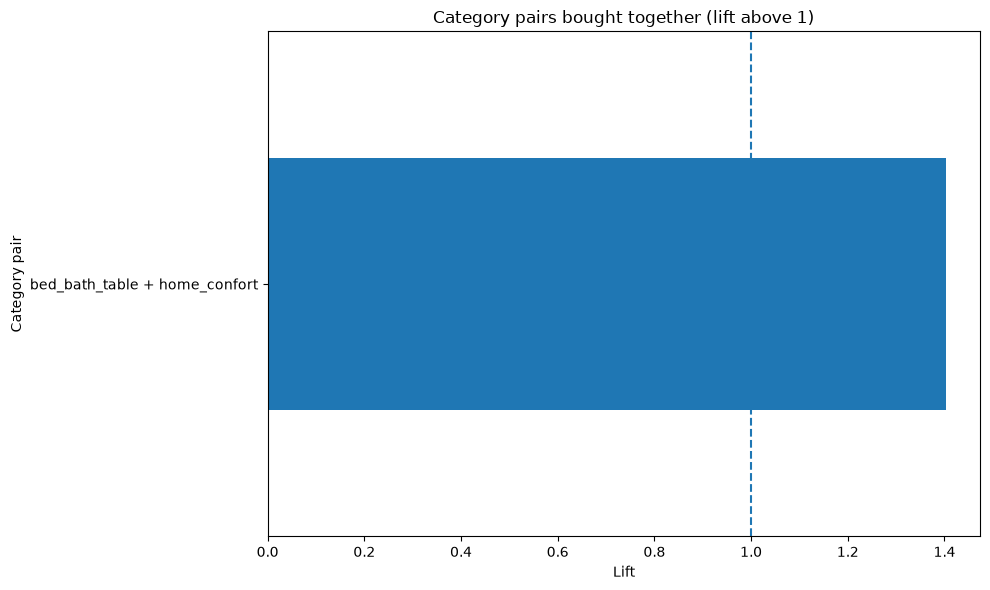

In [127]:
chart_pairs = strong_customer if not strong_customer.empty else strong_order
if chart_pairs.empty:
    print("No pair met the display rules, so there is nothing to chart.")
else:
    chart_pairs = chart_pairs.head(12).copy()
    chart_pairs["pair"] = chart_pairs["category_A"] + " + " + chart_pairs["category_B"]
    chart_pairs = chart_pairs.sort_values("lift")
    ax = chart_pairs.plot(x="pair", y="lift", kind="barh", legend=False, figsize=(10, 6),
                          title="Category pairs bought together (lift above 1)")
    ax.axvline(1, linestyle="--")
    ax.set_xlabel("Lift")
    ax.set_ylabel("Category pair")
    plt.tight_layout()
    plt.show()

### What I have found
- In my run at order level, there were 98,666 baskets. Only one pair had at least 20 orders and a lift above 1: bed_bath_table + home_confort (43 orders, lift about 1.12). This is a weak link.
- Pairs with more orders, such as bed_bath_table + furniture_decor (70 orders), had a lift below 1. So they are bought together less than chance, even though the count looks big.
- The main reason for so few results is that almost all orders contain only one category. The printed lines above give the exact share at order and customer level.
- The customer-level results are printed above. They show whether looking across several orders finds more pairs than looking at single orders.

### How this can help increase sales
- by Testing recommendations, not big campaigns, Showing home_confort products to people buying bed_bath_table items, and the other way round.
- by Testing small bundles with a discount and comparing them to a group with no bundle (an A/B test).
- Encouraging bigger baskets because very few orders have more than one category, the biggest chance may be to get customers to add a second category (for example, "add to your order" offers or a free-freight threshold). Freight is a real cost, so one shipment with many items can also help.
- Do not expect large gains from the current pairs since the link is weak and based on few orders, so the effect must be measured before the company relies on it.

## 4. Task 3 - Seller segmentation by sales and service

I will build one row per seller with these measures:
- **Sales:** total sales value, number of orders, average item price, average freight.
- **Service:** average delivery days, late-delivery rate, average review score.

I will then use K-Means to group similar sellers. My choices and reasons:
- **Only sellers with 5 or more orders are clustered.** Sellers with 1 or 2 orders give unstable averages. I will treat the others as their own group ("low activity") so no seller is left out.
- **Log values for sales and orders**, and **scaling for all measures**, because sales are very skewed and the measures use different units.
- **The number of groups (k) will be chosen from the data.** I will test k = 2 to 8 and pick the best silhouette score between 3 and 6. I stop at 6 so that the groups stay easy to manage.

I will treat the groups as descriptions of sellers, not as permanent labels.

In [128]:
seller_metrics = item_data.groupby("seller_id").agg(
    sales_value=("price", "sum"),
    item_count=("order_item_id", "count"),
    order_count=("order_id", "nunique"),
    average_item_price=("price", "mean"),
    average_freight=("freight_value", "mean"),
    average_distance_km=("distance_km", "mean")
).reset_index()

seller_order_rows = item_data[
    ["seller_id", "order_id", "order_purchase_timestamp",
     "order_delivered_customer_date", "order_estimated_delivery_date"]
].drop_duplicates(["seller_id", "order_id"]).copy()

seller_order_rows["delivery_days"] = (
    seller_order_rows["order_delivered_customer_date"] -
    seller_order_rows["order_purchase_timestamp"]
).dt.total_seconds() / 86400

seller_order_rows["late_flag"] = np.where(
    seller_order_rows["order_delivered_customer_date"].notna(),
    (seller_order_rows["order_delivered_customer_date"] >
     seller_order_rows["order_estimated_delivery_date"]).astype(float),
    np.nan
)

service_metrics = seller_order_rows.groupby("seller_id").agg(
    average_delivery_days=("delivery_days", "mean"),
    late_rate=("late_flag", "mean"),
    delivered_orders=("delivery_days", "count")
).reset_index()

seller_profile = seller_metrics.merge(service_metrics, on="seller_id", how="left")

if reviews is not None and "review_score" in reviews.columns:
    order_seller = item_data[["order_id", "seller_id"]].drop_duplicates()
    review_seller = (
        reviews.merge(order_seller, on="order_id", how="inner")
        .groupby("seller_id")["review_score"].mean()
        .rename("average_review_score").reset_index()
    )
    seller_profile = seller_profile.merge(review_seller, on="seller_id", how="left")

display(seller_profile.describe().T.round(2))

sorted_sales = seller_profile["sales_value"].sort_values(ascending=False)
top10_share = sorted_sales.head(int(len(sorted_sales) * 0.10)).sum() / sorted_sales.sum()
print(f"I found {len(seller_profile):,} sellers. The top 10% of sellers make {top10_share:.1%} of all sales.")
print(f"I found that {(seller_profile['order_count'] < 5).mean():.1%} of sellers have fewer than 5 orders.")

,count,mean,std,min,25%,50%,75%,max
sales_value,3095.0,4391.48,13922.00,3.50,208.85,821.48,3280.83,229472.63
item_count,3095.0,36.40,119.19,1.00,2.00,8.00,24.00,2033.00
order_count,3095.0,32.31,105.14,1.00,2.00,6.00,21.50,1854.00
average_item_price,3095.0,176.33,322.15,3.50,52.18,95.47,173.99,6729.00
average_freight,3095.0,23.38,18.96,1.20,14.74,18.23,24.37,308.34
average_distance_km,3088.0,612.71,394.11,1.14,376.31,549.27,758.09,2798.84
average_delivery_days,2970.0,12.22,7.16,1.21,8.41,11.16,14.24,189.86
late_rate,2970.0,0.08,0.17,0.00,0.00,0.00,0.10,1.00
delivered_orders,3095.0,31.60,103.46,0.00,2.00,6.00,21.00,1819.00
average_review_score,3090.0,4.00,0.96,1.00,3.77,4.19,4.60,5.00


I found 3,095 sellers. The top 10% of sellers make 67.5% of all sales.
I found that 42.0% of sellers have fewer than 5 orders.


,k,inertia,silhouette
0,2,10029.331,0.230
1,3,8141.282,0.250
2,4,6636.889,0.272
3,5,6028.776,0.228
4,6,5594.741,0.193
5,7,5228.795,0.197
6,8,4894.294,0.198


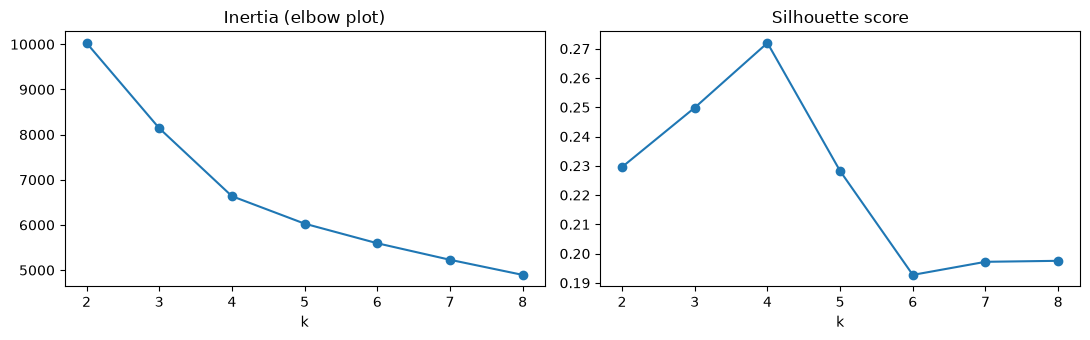

I found that k = 4 has the best silhouette score between 3 and 6, so I will use 4 groups.


In [129]:
MIN_ORDERS = 5
seller_cluster_data = seller_profile[seller_profile["order_count"].fillna(0) >= MIN_ORDERS].copy()

seller_cluster_data["log_sales"] = np.log1p(seller_cluster_data["sales_value"].clip(lower=0))
seller_cluster_data["log_orders"] = np.log1p(seller_cluster_data["order_count"].clip(lower=0))
model_features = [
    "log_sales", "log_orders", "average_item_price",
    "average_freight", "average_delivery_days", "late_rate"
]
has_review = "average_review_score" in seller_cluster_data.columns
if has_review:
    model_features.append("average_review_score")

X_imp = SimpleImputer(strategy="median").fit_transform(seller_cluster_data[model_features])
X_scaled = StandardScaler().fit_transform(X_imp)

k_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    k_rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_scaled, km.labels_)})
k_table = pd.DataFrame(k_rows)
display(k_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_table["k"], k_table["inertia"], marker="o"); axes[0].set_title("Inertia (elbow plot)"); axes[0].set_xlabel("k")
axes[1].plot(k_table["k"], k_table["silhouette"], marker="o"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

best_k = int(k_table[k_table["k"].between(3, 6)].sort_values("silhouette", ascending=False).iloc[0]["k"])
print(f"I found that k = {best_k} has the best silhouette score between 3 and 6, so I will use {best_k} groups.")

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
seller_cluster_data["seller_segment"] = kmeans.fit_predict(X_scaled)

seller_profile = seller_profile.merge(
    seller_cluster_data[["seller_id", "seller_segment"]], on="seller_id", how="left"
)

### Naming each segment and choosing an action

I am going to describe each group with simple rules, compared with all active sellers:
- **High sales:** the group's median sales is above the median of all active sellers.
- **Weak service:** the group's late rate is above the average late rate, or its review score is more than 0.25 below the average review score.

Then I will print a profile and a suggested action for every group, including the low-activity sellers.

In [130]:
segment_summary = seller_cluster_data.groupby("seller_segment").agg(
    sellers=("seller_id", "count"),
    median_sales=("sales_value", "median"),
    median_orders=("order_count", "median"),
    median_item_price=("average_item_price", "median"),
    median_delivery_days=("average_delivery_days", "median"),
    median_late_rate=("late_rate", "median"),
    median_freight=("average_freight", "median")
)
if has_review:
    segment_summary["median_review_score"] = seller_cluster_data.groupby("seller_segment")["average_review_score"].median()
display(segment_summary.round(2))

sales_cut = seller_cluster_data["sales_value"].median()
late_cut = seller_cluster_data["late_rate"].mean()
review_cut = seller_cluster_data["average_review_score"].mean() if has_review else None

actions = {
    (True, False):  ("High sales, strong service",
                     "Keep them. Give account managers, early access to campaigns and rewards for good service."),
    (True, True):   ("High sales, weak service",
                     "Protect the customer experience. Give delivery coaching and watch late orders closely, because problems here reach many customers."),
    (False, False): ("Lower sales, strong service",
                     "Help them grow. Give more visibility, promotions and onboarding tips."),
    (False, True):  ("Lower sales, weak service",
                     "Give basic training and clear service targets. Review again after a set time and act if there is no improvement."),
}

segment_names = {}
print("\n--- Segment profiles ---")
for seg, row in segment_summary.iterrows():
    high_sales = row["median_sales"] >= sales_cut
    weak = row["median_late_rate"] > late_cut
    if has_review and pd.notna(row.get("median_review_score")):
        weak = weak or (row["median_review_score"] < review_cut - 0.25)
    name, action = actions[(bool(high_sales), bool(weak))]
    segment_names[seg] = f"Segment {seg}: {name}"
    review_text = f", review score {row['median_review_score']:.2f}" if has_review and pd.notna(row.get("median_review_score")) else ""
    print(f"I found {segment_names[seg]} - {int(row['sellers'])} sellers, median sales {row['median_sales']:,.0f}, "
          f"{row['median_orders']:.0f} orders, late rate {row['median_late_rate']:.1%}{review_text}.")
    print(f"   Suggested action: {action}")

n_low = int((seller_profile["order_count"] < MIN_ORDERS).sum())
print(f"\nI found {n_low:,} low-activity sellers (fewer than {MIN_ORDERS} orders).")
print("   Suggested action: Run a welcome and onboarding programme (first-sale help, listing tips). Check them again once they pass 5 orders.")

seller_profile["segment_name"] = seller_profile["seller_segment"].map(segment_names).fillna("Low activity (<5 orders)")

,sellers,median_sales,median_orders,median_item_price,median_delivery_days,median_late_rate,median_freight,median_review_score
seller_segment,,,,,,,,
0,72,8745.12,11.0,797.79,13.79,0.07,63.91,4.20
1,620,8154.55,68.0,111.38,12.27,0.07,18.60,4.14
2,812,1040.00,10.0,80.53,9.67,0.00,17.35,4.36
3,290,1498.47,11.0,99.93,16.81,0.20,19.36,3.64



--- Segment profiles ---
I found Segment 0: High sales, strong service - 72 sellers, median sales 8,745, 11 orders, late rate 6.7%, review score 4.20.
   Suggested action: Keep them. Give account managers, early access to campaigns and rewards for good service.
I found Segment 1: High sales, strong service - 620 sellers, median sales 8,155, 68 orders, late rate 6.7%, review score 4.14.
   Suggested action: Keep them. Give account managers, early access to campaigns and rewards for good service.
I found Segment 2: Lower sales, strong service - 812 sellers, median sales 1,040, 10 orders, late rate 0.0%, review score 4.36.
   Suggested action: Help them grow. Give more visibility, promotions and onboarding tips.
I found Segment 3: Lower sales, weak service - 290 sellers, median sales 1,498, 11 orders, late rate 20.0%, review score 3.64.
   Suggested action: Give basic training and clear service targets. Review again after a set time and act if there is no improvement.

I found 1,301 low-

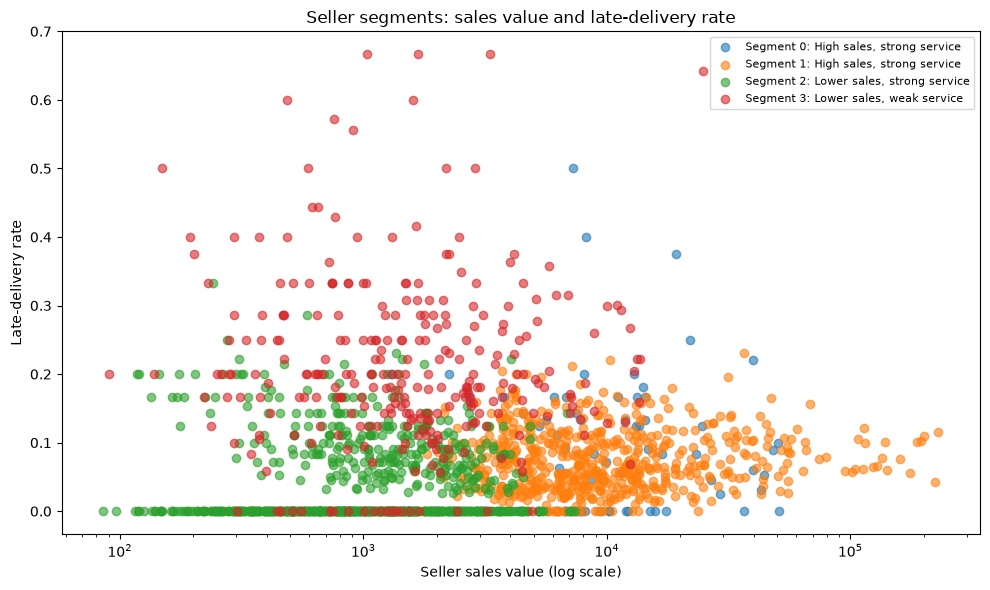

In [131]:
plt.figure(figsize=(10, 6))
for seg in sorted(seller_cluster_data["seller_segment"].unique()):
    part = seller_cluster_data[seller_cluster_data["seller_segment"] == seg]
    plt.scatter(part["sales_value"], part["late_rate"], alpha=0.6, label=segment_names[seg])
plt.xscale("log")
plt.xlabel("Seller sales value (log scale)")
plt.ylabel("Late-delivery rate")
plt.title("Seller segments: sales value and late-delivery rate")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

### What I have seen and what I recommend
- The segment profiles, sizes and suggested actions are printed above. I used the data to decide which group is "high sales" or "weak service".
- Sales are concentrated in a small number of sellers. Losing a few large sellers would hurt the marketplace, so the high-sales groups need the most care.
- A large part of the sellers have fewer than 5 orders. They are not in the clusters, so I gave them their own onboarding action.

**How Olist can serve and keep each group**

| Group | What Olist can do |
|---|---|
| High sales, strong service | Account managers, early access to campaigns, rewards for good service. |
| High sales, weak service | Delivery coaching and close monitoring of late orders. |
| Lower sales, strong service | More visibility, promotions and growth tips. |
| Lower sales, weak service | Basic training, clear targets, review after a set time. |
| Low activity | Welcome programme and first-sales support. |

I will not punish a seller based on a few orders. Seller location, product type and shipping method also affect delivery, so I should compare sellers fairly.

## 5. Task 4 - Unusual orders that need operational review

### Here what i am going to do is
I will build a short ranked list of orders to review, an unusual order is a lead for review, not proof of fraud.

I will use two methods together:
1. **Isolation Forest** finds orders that are unusual across many measures at once.
2. **Simple rules** explain why an order looks unusual. I use the top 1% of each measure instead of the IQR rule. The IQR rule does not work for item count, because almost every order has 1 item.

Rules I will use: very high order value, very high freight, freight that is very high compared with the price, 5 or more items, very long delivery time, payment that does not match price + freight, cancelled or unavailable orders, and orders that are "stuck" (not finished long after the promised date).

Queue rule where an order enters the review queue if it is an Isolation Forest outlier and has at least one rule flag, or if it has two or more rule flags. This keeps the queue short.

Delivery time is only known after delivery, so this review is done after the fact, not at the moment of purchase.

In [132]:
anomaly_data = order_data.copy()
anomaly_data["approval_hours"] = (
    anomaly_data["order_approved_at"] - anomaly_data["order_purchase_timestamp"]
).dt.total_seconds() / 3600
anomaly_data["freight_ratio"] = anomaly_data["freight_value"] / anomaly_data["sales_value"].clip(lower=1)
anomaly_data["payment_gap"] = (
    anomaly_data["payment_value"] - (anomaly_data["sales_value"] + anomaly_data["freight_value"])
).abs()

n_no_items = anomaly_data["sales_value"].isna().sum()
anomaly_data = anomaly_data.dropna(subset=["sales_value", "freight_value"]).copy()
print(f"I found {n_no_items:,} orders with no item data. I leave them out of the model (they were mostly unavailable or cancelled).")

anomaly_data["delivery_known"] = anomaly_data["delivery_days"].notna().astype(int)

anomaly_features = [
    "sales_value", "freight_value", "freight_ratio", "n_items", "n_sellers",
    "total_weight_g", "total_volume_cm3", "distance_km", "approval_hours",
    "delivery_days", "delivery_known", "installments", "payment_gap"
]
X_anom = anomaly_data[anomaly_features].replace([np.inf, -np.inf], np.nan)
X_anom = X_anom.apply(lambda col: col.fillna(col.median()))

for col in ["sales_value", "freight_value", "freight_ratio", "n_items", "n_sellers",
            "total_weight_g", "total_volume_cm3", "distance_km", "approval_hours",
            "installments", "payment_gap"]:
    X_anom[col] = np.log1p(X_anom[col].clip(lower=0))

iso = IsolationForest(n_estimators=250, contamination=0.02, random_state=RANDOM_STATE)
anomaly_data["isolation_flag"] = iso.fit_predict(X_anom)
anomaly_data["anomaly_score"] = -iso.score_samples(X_anom)
anomaly_data["unusual_order"] = anomaly_data["isolation_flag"].eq(-1)

# Simple rule flags
def top_1_percent(series):
    return series > series.quantile(0.99)

last_date = orders["order_purchase_timestamp"].max()
open_status = ~anomaly_data["order_status"].isin(["delivered", "canceled", "unavailable"])

anomaly_data["high_value_flag"] = top_1_percent(anomaly_data["sales_value"])
anomaly_data["high_freight_flag"] = top_1_percent(anomaly_data["freight_value"])
anomaly_data["freight_vs_price_flag"] = top_1_percent(anomaly_data["freight_ratio"])
anomaly_data["many_items_flag"] = anomaly_data["n_items"] >= 5
anomaly_data["long_delivery_flag"] = top_1_percent(anomaly_data["delivery_days"].fillna(0))
anomaly_data["payment_mismatch_flag"] = (
    (anomaly_data["payment_gap"] > 5) &
    (anomaly_data["payment_gap"] > 0.05 * (anomaly_data["sales_value"] + anomaly_data["freight_value"]))
)
anomaly_data["cancelled_flag"] = anomaly_data["order_status"].isin(["canceled", "unavailable"])
anomaly_data["stuck_flag"] = open_status & (
    anomaly_data["order_estimated_delivery_date"] < last_date - pd.Timedelta(days=30)
)

flag_names = {
    "high_value_flag": "very high value",
    "high_freight_flag": "very high freight",
    "freight_vs_price_flag": "freight high vs price",
    "many_items_flag": "5+ items",
    "long_delivery_flag": "very long delivery",
    "payment_mismatch_flag": "payment mismatch",
    "cancelled_flag": "cancelled/unavailable",
    "stuck_flag": "stuck order",
}
anomaly_data["rule_flag_count"] = anomaly_data[list(flag_names)].sum(axis=1)

# Review queue
in_queue = (
    (anomaly_data["unusual_order"] & (anomaly_data["rule_flag_count"] >= 1))
    | (anomaly_data["rule_flag_count"] >= 2)
)
review_queue = anomaly_data[in_queue].copy()
review_queue = review_queue.sort_values(["rule_flag_count", "anomaly_score"], ascending=False)

def reasons(row):
    items_ = [text for col, text in flag_names.items() if row[col]]
    if row["unusual_order"]:
        items_.append("unusual overall pattern")
    return ", ".join(items_)
review_queue["reasons"] = review_queue.apply(reasons, axis=1)

review_columns = [
    "order_id", "order_status", "sales_value", "freight_value", "n_items",
    "delivery_days", "review_score", "anomaly_score", "rule_flag_count", "reasons"
]
display(review_queue[review_columns].head(25).round(2))

print(f"I found {len(review_queue):,} orders for the review queue ({len(review_queue) / len(anomaly_data):.1%} of orders).")
print("I suggest reviewing the top 200 first (highest flag count, then highest score).")

# Do the flagged orders look different on a measure the model did not use?
if anomaly_data["review_score"].notna().any():
    queue_review = review_queue["review_score"].mean()
    other_review = anomaly_data.loc[~in_queue, "review_score"].mean()
    print(f"I found that queue orders have an average review score of {queue_review:.2f}, compared with {other_review:.2f} for other orders.")

I found 775 orders with no item data. I leave them out of the model (they were mostly unavailable or cancelled).


,order_id,order_status,sales_value,freight_value,n_items,delivery_days,review_score,anomaly_score,rule_flag_count,reasons
20074,cf4659487be50c0c317cff3564c4a840,delivered,1050.00,1794.96,6.0,13.77,5.0,0.69,4,"very high value, very high freight, freight hi..."
26525,a9c8ac0c26c178f0ad33618f96225a01,canceled,1795.00,155.20,5.0,NaN,2.0,0.68,4,"very high value, very high freight, 5+ items, ..."
16335,71dab1155600756af6de79de92e712e3,delivered,1361.89,626.64,11.0,39.02,3.0,0.71,3,"very high value, very high freight, 5+ items, ..."
48686,6e5fe7366a2e1bfbf3257dba0af1267f,delivered,179.19,108.72,6.0,7.60,1.0,0.69,3,"very high freight, 5+ items, payment mismatch,..."
88849,8272b63d03f5f79c56e9e4120aec44ef,delivered,31.80,164.37,21.0,14.99,1.0,0.69,3,"very high freight, freight high vs price, 5+ i..."
63700,2455cbeb73fd04b170ca2504662f95ce,delivered,419.40,1002.29,6.0,10.00,1.0,0.68,3,"very high freight, freight high vs price, 5+ i..."
48140,8f6f263a5e96515d5534199b74cb7748,delivered,1319.40,283.68,6.0,17.42,5.0,0.68,3,"very high value, very high freight, 5+ items, ..."
33590,1c49e3fd28c9c369b12fd84446e475ab,processing,1540.00,142.92,4.0,NaN,1.0,0.68,3,"very high value, very high freight, stuck orde..."
52245,6a2726fdb7d200560870b229000f73db,delivered,399.95,177.97,5.0,65.79,5.0,0.68,3,"very high freight, 5+ items, very long deliver..."
27844,31dd19623d916b1848334732b797d5f5,processing,221.40,125.04,6.0,NaN,1.0,0.67,3,"very high freight, 5+ items, stuck order, unus..."


I found 1,400 orders for the review queue (1.4% of orders).
I suggest reviewing the top 200 first (highest flag count, then highest score).
I found that queue orders have an average review score of 2.88, compared with 4.12 for other orders.


,orders
Isolation Forest outliers,1974
very high value,986
very high freight,987
freight high vs price,983
5+ items,460
very long delivery,987
payment mismatch,168
cancelled/unavailable,467
stuck order,1720
IN REVIEW QUEUE,1400


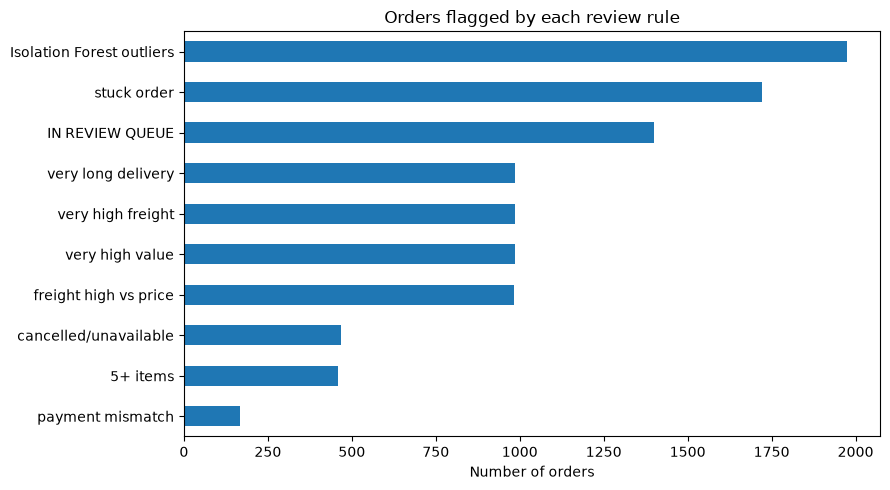

In [133]:
flag_summary = pd.Series({
    "Isolation Forest outliers": anomaly_data["unusual_order"].sum(),
    **{text: anomaly_data[col].sum() for col, text in flag_names.items()},
    "IN REVIEW QUEUE": len(review_queue),
}, name="orders")
display(flag_summary.to_frame())

plt.figure(figsize=(9, 5))
flag_summary.sort_values().plot(kind="barh")
plt.title("Orders flagged by each review rule")
plt.xlabel("Number of orders")
plt.tight_layout()
plt.show()

### What I have seen and what I recommend
- The review queue is printed above with the reason for each order. I made it short on purpose, because a queue with almost 1 in 5 orders cannot be reviewed by a team. (My first version had 19,135 orders. One cause was the item-count rule, which flagged every order with more than one item.)
- Each order in the queue has a plain-language reason, so a reviewer knows where to start.
- I also checked the queue against review scores, which the model did not use. The printed line above shows whether flagged orders really have worse customer experience.

**How Olist can use the queue**
- High value or payment mismatch which helps check against payment and seller records.
- High freight, or freight high compared with price to check package size, distance and carrier price.
- 5 or more items by checking picking, packing and stock handling.
- Very long delivery or stuck orders by checking for carrier delay, wrong address or slow seller dispatch.
- Cancelled or unavailable by checking if the same sellers repeat.

The 2% Isolation Forest setting is a review capacity choice, not a measured fraud rate. Olist should tune it to the size of its review team and track false alarms.

## 6. Task 5 - Predicting late delivery and delivery time

I will build two kinds of model:
1. **Classification:** will the order arrive after the estimated delivery date? (late = 1)
2. **Regression:** how many days will it take from purchase to delivery?

My choices and reasons:
- **Only delivered orders** with known dates and distance, because only these have a real outcome. Orders over 90 days are removed as extreme. I will check how many this removes.
- **Time-based split:** orders before 1 April 2018 train the model, and later orders test it. This is closer to real use than a random split, because a real model predicts the future.
- **Prediction time:** after the order is approved. The model uses approval time and order details, but nothing from after the order is handed to the carrier. The estimated delivery date is known when the order is placed, so I include it.
- **Several models for each task.** I will compare a simple baseline, a linear model and a gradient-boosting model, so I can see if the more complex model is worth it.

In [134]:
delivery = order_data[
    (order_data["order_status"] == "delivered")
    & order_data["order_delivered_customer_date"].notna()
    & order_data["distance_km"].notna()
    & order_data["late"].notna()
].copy()

n_before_cap = len(delivery)
delivery = delivery[delivery["delivery_days"].between(0, 90, inclusive="both")].copy()
print(f"I found that the 90-day limit removed {n_before_cap - len(delivery):,} orders ({(n_before_cap - len(delivery)) / n_before_cap:.2%} of usable delivered orders).")

purchase_time = delivery["order_purchase_timestamp"]
delivery["approval_hours"] = (delivery["order_approved_at"] - purchase_time).dt.total_seconds() / 3600
delivery["approval_hours"] = delivery["approval_hours"].clip(0, 200)

delivery["month"] = purchase_time.dt.month
delivery["day_of_week"] = purchase_time.dt.dayofweek
delivery["purchase_hour"] = purchase_time.dt.hour
delivery["same_state"] = (delivery["customer_state"] == delivery["seller_state"]).astype(int)
delivery["freight_ratio"] = delivery["freight_value"] / delivery["sales_value"].clip(lower=1)

categorical_features = ["customer_state", "seller_state", "first_category", "payment_type"]
numeric_features = [
    "sales_value", "freight_value", "freight_ratio",
    "total_weight_g", "total_volume_cm3", "n_items", "n_sellers",
    "distance_km", "estimated_days", "approval_hours",
    "month", "day_of_week", "purchase_hour", "same_state", "installments"
]

for col in categorical_features:
    delivery[col] = delivery[col].fillna("unknown").astype("category")
for col in numeric_features:
    delivery[col] = pd.to_numeric(delivery[col], errors="coerce")

features = numeric_features + categorical_features

cutoff = pd.Timestamp("2018-04-01")
train = delivery[delivery["order_purchase_timestamp"] < cutoff].copy()
test = delivery[delivery["order_purchase_timestamp"] >= cutoff].copy()

if train.empty or test.empty:
    raise ValueError("The time-based split produced an empty train or test set. Check the dataset date range and adjust cutoff.")
if train["late"].nunique() < 2:
    raise ValueError("Training data contains only one late-delivery class; classification cannot be fitted.")

y_train = train["late"].astype(int)
y_test = test["late"].astype(int)

print(f"Training orders: {len(train):,}")
print(f"Testing orders:  {len(test):,}")
print(f"I found a late rate of {train['late'].mean():.1%} in training and {test['late'].mean():.1%} in testing.")

def make_linear_pipeline(model):
    numeric_steps = Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    prep = ColumnTransformer([
        ("num", numeric_steps, numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])
    return Pipeline([("prep", prep), ("model", model)])

I found that the 90-day limit removed 77 orders (0.08% of usable delivered orders).
Training orders: 63,918
Testing orders:  31,999
I found a late rate of 9.0% in training and 6.0% in testing.


The model has 63,918 training orders and 31,999 test orders. The late rate fell from 9.0% in training to 6.0% in testing. This means the test period was calmer than the training period, so the model is being tested on slightly different conditions. This is one reason why scores in a real setting could differ.

### 6.1 Late-delivery classification

I will compare three approaches:
- **Baseline:** use only the estimated delivery time (a shorter promise means a higher chance of being late).
- **Logistic regression:** a simple, easy-to-explain linear model.
- **Gradient boosting (HistGradientBoosting):** a stronger model that can find non-linear patterns.

I will measure **ROC-AUC** (how well late orders are ranked above on-time orders) and **PR-AUC** (more useful here because late orders are rare). Then I will test different alert thresholds, because the best threshold depends on the cost of checking an order against the cost of a late delivery. Finally I will check which features matter most.

,ROC-AUC,PR-AUC
model,,
Baseline (estimated days only),0.676,0.175
Logistic regression,0.727,0.137
Gradient boosting,0.704,0.128


I found that the best classifier by ROC-AUC is: Logistic regression (0.727).
I found that a random model would have a PR-AUC of about 0.060 (the late rate). The gradient boosting model reached 0.128.

Classification report (gradient boosting, threshold 0.5):
              precision    recall  f1-score   support

           0       0.95      0.86      0.90     30081
           1       0.14      0.36      0.20      1918

    accuracy                           0.83     31999
   macro avg       0.55      0.61      0.55     31999
weighted avg       0.91      0.83      0.86     31999



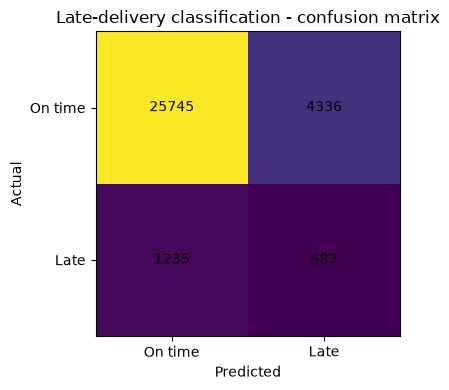

,threshold,orders_flagged_percent,precision,recall,f1
0,0.3,55.767,0.087,0.813,0.158
1,0.4,32.723,0.109,0.595,0.184
2,0.5,15.685,0.136,0.356,0.197
3,0.6,4.831,0.187,0.151,0.167
4,0.7,0.538,0.215,0.019,0.035


In [135]:
# 1. Baseline, shorter promised time = higher risk
base_scores = -test["estimated_days"].fillna(test["estimated_days"].median())

# 2. Logistic regression
logit = make_linear_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"))
logit.fit(train[features], y_train)
logit_proba = logit.predict_proba(test[features])[:, 1]

# 3. Gradient boosting
classifier = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.05, max_leaf_nodes=20,
    categorical_features="from_dtype", class_weight="balanced",
    random_state=RANDOM_STATE
)
classifier.fit(train[features], y_train)
late_probability = classifier.predict_proba(test[features])[:, 1]

cls_compare = pd.DataFrame({
    "model": ["Baseline (estimated days only)", "Logistic regression", "Gradient boosting"],
    "ROC-AUC": [roc_auc_score(y_test, base_scores), roc_auc_score(y_test, logit_proba), roc_auc_score(y_test, late_probability)],
    "PR-AUC": [average_precision_score(y_test, base_scores), average_precision_score(y_test, logit_proba), average_precision_score(y_test, late_probability)],
}).set_index("model")
display(cls_compare.round(3))

best_cls = cls_compare["ROC-AUC"].idxmax()
print(f"I found that the best classifier by ROC-AUC is: {best_cls} ({cls_compare.loc[best_cls, 'ROC-AUC']:.3f}).")
print(f"I found that a random model would have a PR-AUC of about {y_test.mean():.3f} (the late rate). "
      f"The gradient boosting model reached {cls_compare.loc['Gradient boosting', 'PR-AUC']:.3f}.")

# Detailed results for gradient boosting at the 0.5 threshold
late_prediction = (late_probability >= 0.5).astype(int)
print("\nClassification report (gradient boosting, threshold 0.5):")
print(classification_report(y_test, late_prediction, zero_division=0))

cm = confusion_matrix(y_test, late_prediction)
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Late-delivery classification - confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["On time", "Late"])
plt.yticks([0, 1], ["On time", "Late"])
for (i, j), value in np.ndenumerate(cm):
    plt.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

# Different alert thresholds mean different workloads.
threshold_rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    flagged = late_probability >= threshold
    threshold_rows.append({
        "threshold": threshold,
        "orders_flagged_percent": flagged.mean() * 100,
        "precision": precision_score(y_test, flagged, zero_division=0),
        "recall": recall_score(y_test, flagged, zero_division=0),
        "f1": f1_score(y_test, flagged, zero_division=0)
    })
display(pd.DataFrame(threshold_rows).round(3))

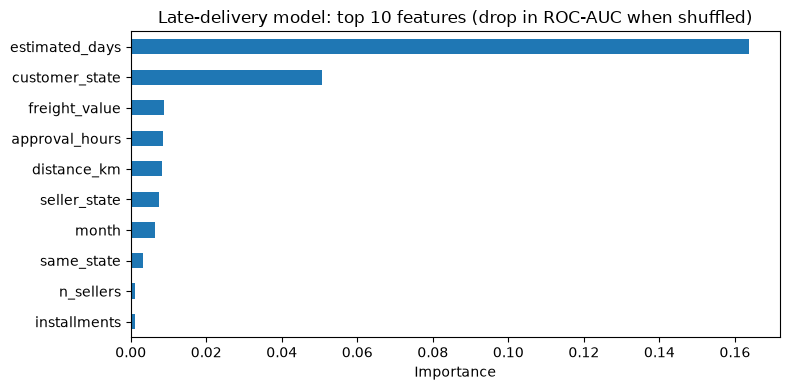

I found that the most important features for predicting late delivery are: estimated_days, customer_state, freight_value, approval_hours, distance_km.


In [136]:
sample = test.sample(min(5000, len(test)), random_state=RANDOM_STATE)
perm_cls = permutation_importance(
    classifier, sample[features], sample["late"].astype(int),
    scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE
)
imp_cls = pd.Series(perm_cls.importances_mean, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
imp_cls.head(10).sort_values().plot(kind="barh")
plt.title("Late-delivery model: top 10 features (drop in ROC-AUC when shuffled)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print("I found that the most important features for predicting late delivery are:", ", ".join(imp_cls.head(5).index) + ".")

**Observed**
- The gradient boosting model reached **ROC-AUC 0.704** and **PR-AUC 0.128**. The late rate in the test set was only 6%, so PR-AUC 0.128 is about twice the random level. This is better than chance but only a modest model.
- At the 0.5 threshold, the model flagged 15.7% of orders. Only 14% of those were really late (precision 0.14), and it caught 36% of all late orders (recall 0.36).
- Lowering the threshold to 0.3 catches 81% of late orders but flags 56% of all orders, and only 8.7% of the alerts are right. Raising it to 0.6 flags only 4.8% of orders with 19% precision, but it misses 85% of late orders.
- The table above compares the three models. It shows whether the extra complexity of gradient boosting is worth it, and the feature chart shows what drives late delivery.

This means that the model can rank orders by risk, but it should not be treated as a reliable yes/no alarm. A sensible use is to watch only the highest-risk orders (for example the top 5%), and to choose the threshold from the real cost of checking an order against the cost of a late delivery.

### 6.2 Delivery-time regression

I will predict the number of days from purchase to delivery. I will compare:
- **Median baseline:** always predict the typical training delivery time.
- **Olist's estimated date:** the promise that customers see.
- **Ridge regression:** a simple linear model.
- **Gradient boosting** with absolute-error loss (less affected by very long deliveries).

I will measure **MAE** (average error in days), **RMSE** (punishes big errors) and **R2** (share of variation explained). The estimated date is a padded promise on purpose, so it is not a fair rival. The median baseline is the fair comparison.

,MAE (days),RMSE (days),R2,within 3 days
model,,,,
Training median baseline,5.522,7.192,-0.068,0.282
Olist estimated date,12.767,15.176,-3.755,0.092
Ridge regression,5.234,6.744,0.061,0.326
Gradient boosting,3.883,5.728,0.323,0.514


I found that the best model by MAE is: Gradient boosting (3.88 days).
I found that gradient boosting cuts the error by 30% compared with the median baseline.


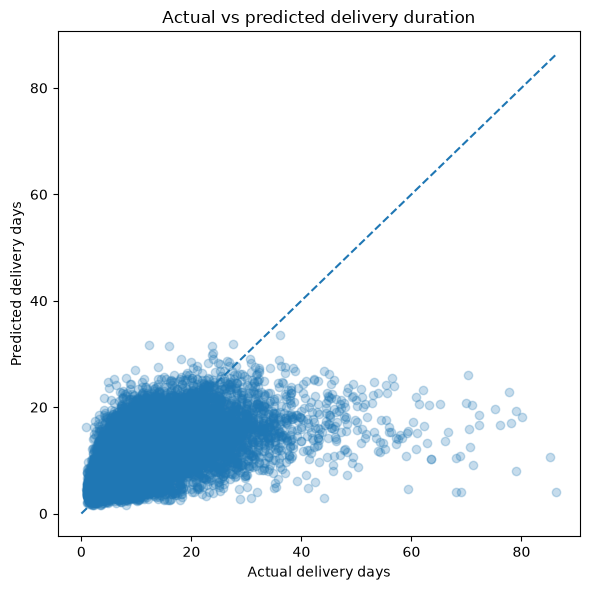

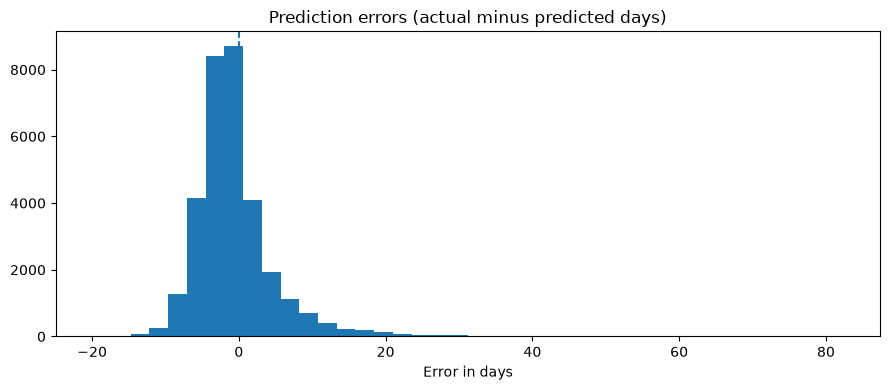

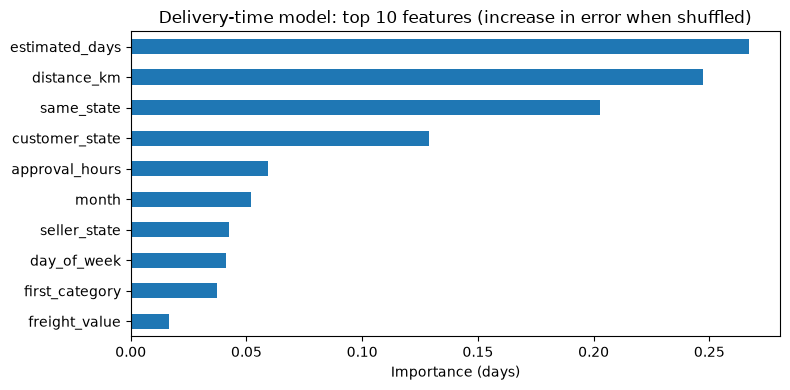

I found that the most important features for predicting delivery time are: estimated_days, distance_km, same_state, customer_state, approval_hours.


In [137]:
def regression_metrics(name, predictions):
    return {
        "model": name,
        "MAE (days)": mean_absolute_error(test["delivery_days"], predictions),
        "RMSE (days)": mean_squared_error(test["delivery_days"], predictions) ** 0.5,
        "R2": r2_score(test["delivery_days"], predictions),
        "within 3 days": (np.abs(test["delivery_days"] - predictions) <= 3).mean(),
    }

median_baseline = np.full(len(test), train["delivery_days"].median())
promise_baseline = test["estimated_days"]

ridge = make_linear_pipeline(Ridge(alpha=1.0))
ridge.fit(train[features], train["delivery_days"])
ridge_pred = ridge.predict(test[features])

regressor = HistGradientBoostingRegressor(
    max_iter=400, learning_rate=0.05, max_leaf_nodes=20,
    categorical_features="from_dtype", loss="absolute_error",
    random_state=RANDOM_STATE
)
regressor.fit(train[features], train["delivery_days"])
predicted_days = regressor.predict(test[features])

reg_compare = pd.DataFrame([
    regression_metrics("Training median baseline", median_baseline),
    regression_metrics("Olist estimated date", promise_baseline),
    regression_metrics("Ridge regression", ridge_pred),
    regression_metrics("Gradient boosting", predicted_days),
]).set_index("model")
display(reg_compare.round(3))

best_reg = reg_compare["MAE (days)"].idxmin()
print(f"I found that the best model by MAE is: {best_reg} ({reg_compare.loc[best_reg, 'MAE (days)']:.2f} days).")
gain = 1 - reg_compare.loc["Gradient boosting", "MAE (days)"] / reg_compare.loc["Training median baseline", "MAE (days)"]
if gain > 0:
    print(f"I found that gradient boosting cuts the error by {gain:.0%} compared with the median baseline.")
else:
    print("I found that gradient boosting does not beat the median baseline on MAE.")

plt.figure(figsize=(6, 6))
plt.scatter(test["delivery_days"], predicted_days, alpha=0.25)
limit = max(test["delivery_days"].max(), np.nanmax(predicted_days))
plt.plot([0, limit], [0, limit], linestyle="--")
plt.xlabel("Actual delivery days")
plt.ylabel("Predicted delivery days")
plt.title("Actual vs predicted delivery duration")
plt.tight_layout()
plt.show()

residuals = test["delivery_days"].to_numpy() - predicted_days
plt.figure(figsize=(9, 4))
plt.hist(residuals, bins=40)
plt.axvline(0, linestyle="--")
plt.title("Prediction errors (actual minus predicted days)")
plt.xlabel("Error in days")
plt.tight_layout()
plt.show()

perm_reg = permutation_importance(
    regressor, sample[features], sample["delivery_days"],
    scoring="neg_mean_absolute_error", n_repeats=3, random_state=RANDOM_STATE
)
imp_reg = pd.Series(perm_reg.importances_mean, index=features).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
imp_reg.head(10).sort_values().plot(kind="barh")
plt.title("Delivery-time model: top 10 features (increase in error when shuffled)")
plt.xlabel("Importance (days)")
plt.tight_layout()
plt.show()
print("I found that the most important features for predicting delivery time are:", ", ".join(imp_reg.head(5).index) + ".")

**Results seen**
- Gradient boosting had an average error (MAE) of **3.88 days**, RMSE of 5.73 days and R2 of 0.32.
- The median baseline had a MAE of 5.52 days, so the model is about **30% more accurate** than a simple guess.
- The prediction was within 3 days of the real value for **51.4%** of orders.
- Olist's estimated date had a MAE of 12.77 days and was within 3 days only 9.2% of the time. This is because the promise is padded on purpose, so I do not treat it as a real competitor. It does show, however, that customers are often told a date that is much later than needed.
- R2 of 0.32 means about two-thirds of the variation is still not explained. Things such as weather, carrier delays and seller dispatch time are not in the data.

This means that the model is useful for giving customers a more realistic delivery estimate and for planning, but it is not very precise for single orders. The comparison table and feature chart above show how the simpler models and the main drivers compare.

### 6.3 How Olist can use the models
- Use the **late-delivery model** to rank approved orders by risk and contact sellers or carriers about the highest-risk ones first.
- Use the **delivery-time model** to show customers a tighter, more honest delivery date, and to spot orders likely to pass their promise.
- **Keep checking** the models over time. Carriers, sellers and seasons change, and the late rate already differed between the training and test periods.
- **Next steps:** tune the models with time-aware validation, try a random forest, and calibrate the late-delivery probabilities.

## 7. Overall business recommendations

- My analysis shows that customers rarely buy products from different categories in the same order, and the relationships between categories are generally weak. I recommend that Olist test product recommendations, bundles and special offers that encourage customers to purchase products from a second category.

- I recommend rewarding sellers who generate high sales and provide good service, while coaching high-selling sellers with service challenges. Olist should also help small but reliable sellers grow and provide guidance to sellers with low activity.

- I recommend that Olist use the unusual-order scores to create a ranked list of orders for review. Each order should include the reasons why it was flagged. These flags should guide further investigation rather than be treated as proof of fraud or wrongdoing.

- My analysis shows that late deliveries are associated with lower customer review scores. I recommend using the prediction models to identify orders at risk of arriving late, take early action and provide customers with more realistic delivery estimates.

- I recommend that Olist test these strategies and monitor the results over time. Key measures should include sales conversion, average basket size, seller retention, late-delivery rates and customer review scores. This will help determine whether the recommended actions are actually improving marketplace performance.

## 8. Limitations

- The data is history. Patterns can change.
- Association rules show co-purchase, not cause. The links found are weak.
- Seller groups depend on the chosen measures, scaling, the 5-order rule and the number of groups.
- Anomalies are unusual orders, not confirmed fraud.
- The delivery models use delivered orders only. They do not predict cancellations or orders that never arrive. The 90-day limit removes some of the worst delays.
- Distance is a straight line between postal-code centres. It is only an estimate of real travel distance.
- The classifier is only a modest model (ROC-AUC about 0.70). It is better used for ranking than for yes/no decisions.
- The prediction point is after order approval. Before using the models live, Olist should confirm that every feature is available at that time.
